# Bantay-Kontrata Tagum

Which City of Tagum awards and tenders look unusual compared with earlier records, and which inputs drive their review scores?

Open this notebook from the GitHub repository in **Google Colab** and select **Runtime → Run all**. A fresh runtime fetches the project and its bundled datasets. In local Jupyter, run from the repository root.

## 1. Load the project

The first cell finds the project and installs its packages. Use a fresh Colab runtime when opening a newer project version.

In [1]:
from pathlib import Path, PurePosixPath
import os
import subprocess
import sys
from zipfile import ZipFile

repository_url = "https://github.com/alilbitofsoulsauce/bantay-kontrata.git"
package_name = "Bantay_Kontrata_Tagum"
required_files = ("requirements.txt", "integration.py", "publish_dashboard.py",
                  "data/official/tagum_philgeps_tenders.csv")
cwd = Path.cwd()
checkout = cwd / "bantay-kontrata"
project = next((path for path in (cwd, checkout, cwd / package_name)
                if all((path / file).is_file() for file in required_files)), None)
if project is None:
    archive = cwd / f"{package_name}.zip"
    if archive.is_file():
        with ZipFile(archive) as zf:
            members = [PurePosixPath(name) for name in zf.namelist()]
            if any(path.is_absolute() or ".." in path.parts or not path.parts or path.parts[0] != package_name for path in members):
                raise ValueError("Choose the Bantay-Kontrata project ZIP.")
            required = {f"{package_name}/{file}" for file in required_files}
            if not required.issubset(zf.namelist()):
                raise ValueError("The ZIP is missing project files or source data.")
            zf.extractall(cwd)
        project = cwd / package_name
    else:
        try:
            import google.colab
        except ImportError as exc:
            raise FileNotFoundError("Clone Bantay-Kontrata and run the notebook from the repository root.") from exc
        if checkout.exists():
            raise FileExistsError("The bantay-kontrata folder is incomplete. Move it or use a fresh Colab runtime.")
        subprocess.run(["git", "clone", "--depth", "1", repository_url, str(checkout)], check=True)
        project = checkout

missing = [file for file in required_files if not (project / file).is_file()]
if missing:
    raise FileNotFoundError("The project is missing these files: " + ", ".join(missing))

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(project / "requirements.txt")], check=True)
sys.path.insert(0, str(project))

## 2. Reconcile the award records and run both screens

An **award** is a published procurement result. A **tender** is the published invitation or request. A tender can yield several awards.

The register joins archive and official awards using the award date, the amount to the cent, the awardee, and the normalized title. The match must be unique on both sides. Cases that share the date, amount and awardee with another unlinked row remain visible for review. In the old archive, the contract number is local. Official numeric award and bid IDs come from the quarterly releases.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from publish_dashboard import analyze, publish
from screen import local_diffi, scenario_amount
from tender_screen import tender_window_scenario

analysis = analyze(project / "data")
data = analysis["data"]
report = analysis["metrics"]
counts = report["coverage"]
print(f"{counts['archive_awards']:,} archive rows + {counts['official_awards']:,} official awards")
print(f"{counts['linked_awards']:,} one-to-one matches → {counts['award_register_rows']:,} register rows")
print(f"{counts['unresolved_register_rows']:,} register rows have possible overlaps.")
display(pd.DataFrame(counts["annual"]).rename(columns={
    "year": "Year", "archive_awards": "Archive awards", "official_awards": "Official awards",
    "matches": "Matches", "award_register_rows": "Register rows", "official_tenders": "Official tenders",
}))

11,305 archive rows + 3,193 official awards
2,198 one-to-one matches → 12,300 register rows
326 register rows have possible overlaps.


,Year,Archive awards,Official awards,Matches,Register rows,Official tenders
0,2017,603,0,0,603,0
1,2018,1048,0,0,1048,0
2,2019,1378,0,0,1378,0
3,2020,1024,0,0,1024,0
4,2021,1443,0,0,1443,0
5,2022,1513,0,0,1513,0
6,2023,1401,0,0,1401,0
7,2024,1578,1871,1395,2054,1403
8,2025,1317,1322,803,1836,1476
9,2026,0,0,0,0,516


## 3. Inspect the training and evaluation periods

The historical award screen compares the amount with its recent peer median and considers vendor activity, category volume, and timing. The tender screen uses budget and bid window relative to peers, earlier mode and classification frequencies, and quarter-end timing.

Both screens use only earlier dates when calculating peer context. The tender screen uses publication fields. Award outcomes and notice status are displayed as evidence.

In [3]:
periods = []
for name, date_field in [("award", "award_date"), ("tender", "published_date")]:
    model = analysis[name]
    for stage in ["Warm-up", "Training", "Calibration", "Evaluation"]:
        rows = model["processed"].loc[model["processed"].split.eq(stage)]
        periods.append({
            "Model": name.title(), "Period": stage, "First date": str(rows[date_field].min())[:10],
            "Last date": str(rows[date_field].max())[:10], "Rows": len(rows),
        })
    flags = report[name]["n_flags"]
    cutoff = model["cutoffs"]["Isolation Forest"]
    print(f"{name.title()}: {flags:,} of {len(model['eval']):,} evaluation rows above the {cutoff:.6f} review cutoff.")
display(pd.DataFrame(periods))

Award: 106 of 1,317 evaluation rows above the 0.538882 review cutoff.
Tender: 48 of 516 evaluation rows above the 0.582367 review cutoff.


,Model,Period,First date,Last date,Rows
0,Award,Warm-up,2017-01-18,2017-12-29,603
1,Award,Training,2018-01-04,2023-12-29,7807
2,Award,Calibration,2024-01-03,2024-12-28,1578
3,Award,Evaluation,2025-01-02,2025-12-08,1317
4,Tender,Warm-up,2024-01-05,2024-03-28,302
5,Tender,Training,2024-04-02,2024-12-28,1101
6,Tender,Calibration,2025-01-10,2025-12-27,1476
7,Tender,Evaluation,2026-01-06,2026-09-26,516


## 4. Read an award and its official bid evidence

The default case is the highest-ranked 2025 review row that links to a tender. The approved budget belongs to that tender. The total below sums the observed official awards linked to the same bid reference.

In [4]:
awards = analysis["award_rows"].sort_values(["anomaly_score", "record_id"], ascending=[False, True]).copy()
awards.insert(0, "rank", range(1, len(awards) + 1))
linked = awards.loc[awards.review & awards.bid_reference.fillna("").ne("")]
award_case = linked.iloc[0]
print(f"{report['coverage']['award_flags_with_official_tender']} flagged award rows link to a tender.")
display(linked.head(4)[["rank", "award_date", "official_award_reference", "bid_reference", "contract_amount", "anomaly_score"]].round(5))
display(award_case[[
    "official_award_reference", "bid_reference", "procurement_mode", "published_date", "closing_date",
    "notice_window_days", "approved_budget_php", "observed_official_awards",
    "observed_official_award_total_php", "official_notice_link",
]].to_frame("Published evidence"))

43 flagged award rows link to a tender.


,rank,award_date,official_award_reference,bid_reference,contract_amount,anomaly_score
855,3,2025-05-30,5592393,12022987,164500.0,0.61980
854,8,2025-05-30,5593092,12025592,206900.0,0.61333
857,9,2025-05-30,5592504,12022793,211800.0,0.61307
858,10,2025-05-30,5593178,12025570,257400.0,0.61293


,Published evidence
official_award_reference,5592393
bid_reference,12022987
procurement_mode,Public Bidding
published_date,2025-05-09
closing_date,2025-05-20
notice_window_days,11.0
approved_budget_php,448882.0
observed_official_awards,2.0
observed_official_award_total_php,447902.0
official_notice_link,https://notices.philgeps.gov.ph/GEPSNONPILOT/T...


## 5. Inspect a 2026 tender

This screen ranks tenders by how easily the forest isolates their combination of values. The evaluation cohort contains published tenders through September. The checked releases contain no dated Tagum awards from 2026.

In [5]:
tenders = analysis["tender"]["eval"].sort_values(["anomaly_score", "bid_reference"], ascending=[False, True]).copy()
tenders.insert(0, "rank", range(1, len(tenders) + 1))
tender_case = tenders.iloc[0]
display(tenders.head(5)[[
    "rank", "bid_reference", "published_date", "procurement_mode", "approved_budget_php",
    "notice_window_days", "anomaly_score", "review",
]].round(5))
print(tender_case.notice_title)
print(tender_case.official_notice_link)

PB-07-14-26 Procurement of Infrastructure Project One (1) lot Construction of Multi-Purpose Building (Gymnasium w/ Stage) at Mel Village, Brgy. Visayan Village, Tagum City (PR300-26-06-00079)
https://notices.philgeps.gov.ph/GEPSNONPILOT/Tender/PrintableBidNoticeAbstractUI.aspx?refid=13103239


,rank,bid_reference,published_date,procurement_mode,approved_budget_php,notice_window_days,anomaly_score,review
318,1,13103239,2026-07-04,Public Bidding,40000000.0,24,0.71463,True
319,2,13103321,2026-07-04,Public Bidding,40000000.0,24,0.71463,True
10,3,12726346,2026-01-16,Public Bidding,80000000.0,25,0.70648,True
5,4,12717616,2026-01-10,Public Bidding,30000000.0,24,0.70198,True
6,5,12717807,2026-01-10,Public Bidding,30000000.0,24,0.70198,True


## 6. Explain a score

TreeSHAP decomposes the original forest's average isolation path. A negative contribution shortens that path, which raises the anomaly score. Local-DIFFI measures feature use in shorter paths. ExIFFI describes each feature's contribution to splits in the separately trained Extended Isolation Forest.

Award at rank 3. Path 7.070 splits, baseline 11.536.
Tender at rank 1. Path 4.966 splits, baseline 11.629.


,Feature,TreeSHAP (splits),Local-DIFFI,ExIFFI
3,Days to quarter end,0.23533,0.02527,4.37453
0,Amount vs. recent peers,0.16896,0.02409,3.96965
1,Vendor's prior award share,-0.12863,0.03074,4.69517
4,Prior awards in category,-0.93695,0.02647,4.52831
2,Recent same-category vendor awards,-3.80425,0.06134,6.19306


,Feature,TreeSHAP (splits),Local-DIFFI,ExIFFI
2,Prior tenders in this procurement mode,-0.06387,0.07620,5.68222
4,Days to quarter end,-0.48366,0.07261,4.95929
1,Bid window vs. recent peers,-1.12821,0.07026,5.72074
0,Budget vs. recent peers,-1.86338,0.09004,5.67089
3,Prior tenders in this classification,-3.12362,0.09625,5.84470


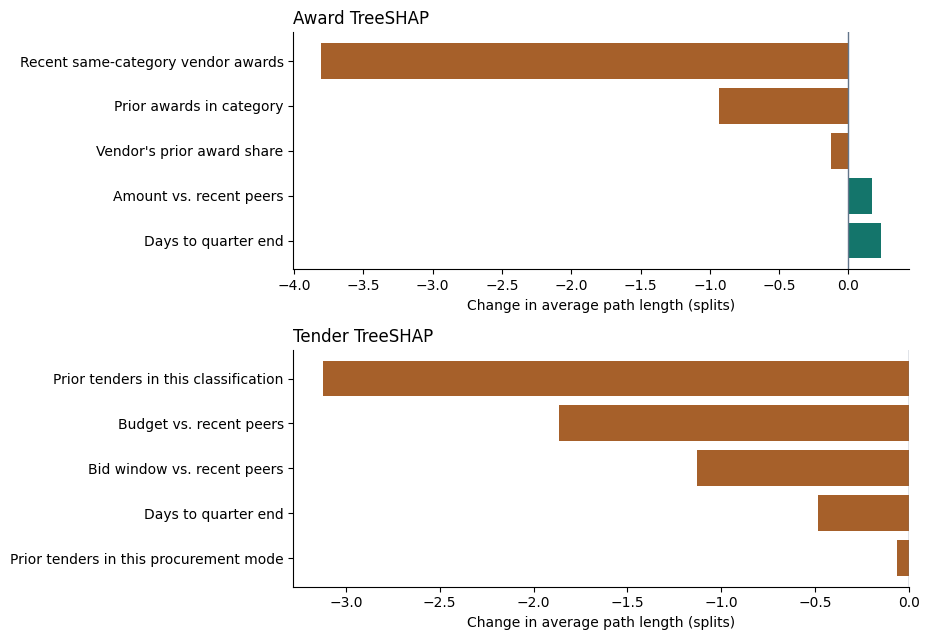

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9.4, 6.5))
for axis, (name, row) in zip(axes, [("award", award_case), ("tender", tender_case)]):
    model = analysis[name]
    index = row.name
    vector = model["views"]["Evaluation"][index]
    table = pd.DataFrame({
        "Feature": list(model["features"].values()),
        "TreeSHAP (splits)": model["effects"][index],
        "Local-DIFFI": local_diffi(model["forest"], vector[None, :])[0],
        "ExIFFI": model["exiffi"][index],
    }).sort_values("TreeSHAP (splits)", ascending=False)
    print(f"{name.title()} at rank {row['rank']}. Path {row.tree_path_length:.3f} splits, baseline {model['tree_base']:.3f}.")
    display(table.round(5))
    values = table["TreeSHAP (splits)"]
    colors = ["#a6602a" if value < 0 else "#14756b" for value in values]
    axis.barh(table.Feature, values, color=colors)
    axis.axvline(0, color="#62758a", linewidth=1)
    axis.set_title(f"{name.title()} TreeSHAP", loc="left")
    axis.set_xlabel("Change in average path length (splits)")
    axis.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 7. Change one input in a what-if test

The award test varies the amount using values observed in its training category. The tender test varies bid-window days using values observed for its training procurement mode. The remaining model inputs are held fixed so the score change can be attributed to the tested input.

In [7]:
for name, row, scenario_for in [
    ("award", award_case, scenario_amount),
    ("tender", tender_case, tender_window_scenario),
]:
    model = analysis[name]
    vector = model["views"]["Evaluation"][row.name]
    change = scenario_for(row, vector, model)
    print(f"{name.title()} peer group: {change['scope']}")
    if change["points"]:
        display(pd.DataFrame(change["points"]).round(6))
    else:
        print("The training peer group is too small for a what-if test.")
    if change["closest"]:
        print("Closest tested value within the cutoff:", change["closest"])

Award peer group: Same business category
Tender peer group: Same procurement mode


,amount,score
0,8050.00,0.657916
1,20700.00,0.644077
2,36509.00,0.635158
3,44200.00,0.632690
4,54720.00,0.630468
5,65422.00,0.626006
6,81000.00,0.621411
7,96225.00,0.619836
8,115490.00,0.618920
9,137700.00,0.619405


,days,score
0,7,0.704707
1,9,0.696635
2,10,0.693402
3,11,0.691937
4,12,0.691582
5,13,0.692753
6,14,0.699001
7,21,0.709512
8,23,0.713725
9,24,0.714631


## 8. Validate rank behavior and explanations

The stress tests replace a small share of held-out inputs with simulated changes. Average precision and recall describe recovery of those changes. Record-level fraud or compliance accuracy needs independently verified labels. The reconstruction error checks that TreeSHAP adds back to the forest's path length. The refit check measures how sensitive the top feature and ranks are to the random seed.

In [8]:
for name in ["award", "tender"]:
    metrics = report[name]
    print(f"{name.title()} model. Maximum TreeSHAP verification error {metrics['maximum_shap_error']:.2e} splits.")
    display(pd.DataFrame(metrics["scenarios"])[["scenario", "method", "ap", "recall", "paired_win"]].round(3))
    display(pd.Series(metrics["stability"], name="Result").round(3).to_frame())

Award model. Maximum TreeSHAP verification error 4.44e-14 splits.
Tender model. Maximum TreeSHAP verification error 3.91e-14 splits.


,scenario,method,ap,recall,paired_win
0,Amount ×0.25,Isolation Forest,0.073,0.108,0.706
1,Amount ×0.25,Extended Isolation Forest,0.072,0.057,0.669
2,Amount ×0.25,Amount-only baseline,0.099,0.112,0.667
3,Amount ×4,Isolation Forest,0.078,0.138,0.799
4,Amount ×4,Extended Isolation Forest,0.083,0.076,0.822
5,Amount ×4,Amount-only baseline,0.132,0.182,0.821
6,Vendor burst,Isolation Forest,0.268,0.755,1.000
7,Vendor burst,Extended Isolation Forest,0.283,0.720,1.000
8,Vendor burst,Amount-only baseline,0.060,0.085,0.500


,Result
refits,8.000
tree_shap_top_feature_agreement,0.976
local_diffi_top_feature_agreement,0.782
score_rank_spearman,0.985


,scenario,method,ap,recall,paired_win
0,Budget ×4,Isolation Forest,0.097,0.087,0.916
1,Budget ×4,Extended Isolation Forest,0.103,0.087,0.868
2,Budget ×4,Budget-only baseline,0.206,0.534,0.913
3,Bid window halved,Isolation Forest,0.106,0.053,0.856
4,Bid window halved,Extended Isolation Forest,0.139,0.087,0.856
5,Bid window halved,Budget-only baseline,0.058,0.130,0.500
6,Budget ×4 and window halved,Isolation Forest,0.151,0.144,0.894
7,Budget ×4 and window halved,Extended Isolation Forest,0.193,0.188,0.952
8,Budget ×4 and window halved,Budget-only baseline,0.204,0.524,0.909


,Result
refits,8.000
tree_shap_top_feature_agreement,0.982
local_diffi_top_feature_agreement,0.841
score_rank_spearman,0.976


## 9. Follow a DPWH project

The infrastructure view uses the DPWH contract ID to attach flood-map identifiers. The map draws published project coordinates inside the Tagum barangay boundaries. Schedule variance is the observed actual completion date minus the target date for completed projects with consistent dates.

In [9]:
projects = pd.read_csv(project / "data" / "tagum_dpwh.csv")
print(f"{len(projects):,} DPWH project records, {projects.barangay.notna().sum():,} mapped points.")
display(data.flood_links[[
    "dpwh_contract_id", "flood_map_project_id", "flood_map_component_id", "barangay", "source_url",
]].head(6))

336 DPWH project records, 235 mapped points.


,dpwh_contract_id,flood_map_project_id,flood_map_component_id,barangay,source_url
0,22LC0030,P00620055MN,P00620055MN-CW1,,https://transparency.dpwh.gov.ph/projects/22LC...
1,22LC0032,P00620084MN,P00620084MN-CW1,San Isidro,https://transparency.dpwh.gov.ph/projects/22LC...
2,22LC0035,P00620219MN,P00620219MN-CW1,Bincungan,https://transparency.dpwh.gov.ph/projects/22LC...
3,22LC0037,P00620222MN,P00620222MN-CW1,Apokon,https://transparency.dpwh.gov.ph/projects/22LC...
4,22LC0040,P00620233MN,P00620233MN-CW1,Pagsabangan,https://transparency.dpwh.gov.ph/projects/22LC...
5,22LC0201,P00632610MN,P00632610MN-CW1,Apokon,https://transparency.dpwh.gov.ph/projects/22LC...


## 10. Export the dashboard and tables

This cell writes the review dashboard, the ranked records, the award register, the link records and the validation metrics to **tagum_review**. Download the HTML from the Colab Files panel and open it in a browser. Use **Record review** on an award or a tender to write down the source evidence and review status. Under **Saved reviews**, export a spreadsheet or download a portable backup for this snapshot.

In [10]:
output = Path.cwd() / "tagum_review"
dashboard = publish(analysis, output, project / "data")
print(dashboard.name)
print("Generated files:", ", ".join(sorted(path.name for path in output.iterdir())))

Bantay_Kontrata_Dashboard.html
Generated files: Bantay_Kontrata_Dashboard.html, tagum_2025_ranked_awards.csv, tagum_2026_ranked_tenders.csv, tagum_award_links.csv, tagum_award_register.csv, tagum_possible_award_overlaps.csv, validation.json


## Source references

- [Official PS-PhilGEPS quarterly data](https://philgeps.gov.ph/CmsHomePages/open-data) and [BetterGov historical award archive](https://huggingface.co/datasets/bettergovph/philgeps-data)
- [DPWH project data dictionary](https://lovethephilippines.com/data) and [Flood-control data mirror](https://github.com/rukku/sumbongsapangulo.ph-datasets)
- [Tagum's barangay PSGC record](https://psa.gov.ph/classification/psgc/barangays/1102319000) and [boundary release](https://bendlikeabamboo.github.io/barangay-boundaries-repository/boundaries/download.html)
- [Isolation Forest](https://doi.org/10.1109/ICDM.2008.17), [TreeSHAP](https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html), [Local-DIFFI](https://arxiv.org/abs/2007.11117), [Extended Isolation Forest](https://arxiv.org/abs/1811.02141) and [ExIFFI](https://arxiv.org/abs/2310.05468)